# GAN көмегімен кескін сапасын жақсарту
**Python · Jupyter Notebook · Real-ESRGAN · PSNR және SSIM**

Бұл notebook алдын ала оқытылған Real-ESRGAN моделін пайдаланып, төмен ажыратымдылықтағы кескінді 4 есе үлкейтеді. Алдымен тәжірибені белгілі өлшемді үлгі суретте тексереміз, содан кейін өз суретіңізді өңдей аласыз.

> **Метрикалар туралы:** PSNR және SSIM есептеу үшін сапалы эталон сурет керек. Сондықтан тәжірибеде 512×512 түпнұсқа суретті 128×128-ге әдейі кішірейтіп, содан кейін қалпына келтіреміз. Осылайша нәтижені бастапқы түпнұсқамен әділ салыстыруға болады.

## 1. Қажетті кітапханаларды орнату

Ұяшықты орындағаннан кейін импорттауда қате шықса, kernel-ді қайта іске қосып, ұяшықтарды басынан орындаңыз. Real-ESRGAN пакеті PyTorch негізінде жұмыс істейді.

In [14]:
%pip install -q realesrgan basicsr facexlib gfpgan opencv-python scikit-image matplotlib pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Кітапханаларды қосу және құрылғыны тексеру

In [15]:
import sys
import types
import torchvision.transforms as transforms
from torchvision.transforms.functional import rgb_to_grayscale

# BasicSR мен жаңа torchvision нұсқаларының үйлесімділігі
compat_module = types.ModuleType(
    "torchvision.transforms.functional_tensor"
)
compat_module.rgb_to_grayscale = rgb_to_grayscale

sys.modules["torchvision.transforms.functional_tensor"] = compat_module
transforms.functional_tensor = compat_module

print("Үйлесімділік түзетуі дайын!")

Үйлесімділік түзетуі дайын!


In [16]:
import os
import urllib.request
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

from basicsr.archs.rrdbnet_arch import RRDBNet
from realesrgan import RealESRGANer

device = "CUDA GPU" if torch.cuda.is_available() else "CPU"
print("Есептеу құрылғысы:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU табылмады. Модель CPU-да жұмыс істейді, бірақ баяуырақ болуы мүмкін.")

Есептеу құрылғысы: CUDA GPU
GPU: NVIDIA GeForce GTX 1650 Ti


## 3. Алдын ала оқытылған модельді жүктеу

`RealESRGAN_x4plus.pth` — жалпы фотосуреттерге арналған, алдын ала оқытылған салмақтар файлы. Біз желіні қайта оқытпаймыз; дайын модельді суретке қолданамыз.

In [17]:
weights_dir = Path("weights")
weights_dir.mkdir(exist_ok=True)
weights_path = weights_dir / "RealESRGAN_x4plus.pth"

weights_url = (
    "https://github.com/xinntao/Real-ESRGAN/releases/download/"
    "v0.1.0/RealESRGAN_x4plus.pth"
)

if not weights_path.exists():
    print("Модель салмақтары жүктелуде...")
    urllib.request.urlretrieve(weights_url, weights_path)

print("Салмақтар файлы:", weights_path.resolve())
print("Файл өлшемі:", round(weights_path.stat().st_size / (1024**2), 1), "MB")

Салмақтар файлы: C:\Users\User\Desktop\Gan\weights\RealESRGAN_x4plus.pth
Файл өлшемі: 63.9 MB


## 4. Real-ESRGAN моделін дайындау

Бұл архитектура 4× үлкейтуге арналған. `tile=0` кескінді тұтас өңдейді; жад жеткіліксіз болса, `tile=256` деп өзгертіп көруге болады.

In [18]:
model = RRDBNet(
    num_in_ch=3,
    num_out_ch=3,
    num_feat=64,
    num_block=23,
    num_grow_ch=32,
    scale=4
)

# GTX 16xx (GTX 1650 Ti) картасында float16 қара сурет береді, сондықтан half=False
upsampler = RealESRGANer(
    scale=4,
    model_path=str(weights_path),
    model=model,
    tile=0,
    tile_pad=10,
    pre_pad=0,
    half=False
)

# Тексеру: модель қара сурет берсе, CPU-ға ауысамыз
test_img = np.full((32, 32, 3), 128, dtype=np.uint8)
test_out, _ = upsampler.enhance(test_img, outscale=4)
if test_out.max() == 0:
    print("GPU қара нәтиже берді, CPU-ға ауысамыз...")
    upsampler = RealESRGANer(
        scale=4,
        model_path=str(weights_path),
        model=model,
        tile=0,
        tile_pad=10,
        pre_pad=0,
        half=False,
        device=torch.device("cpu")
    )

print("Real-ESRGAN моделі дайын. Құрылғы:", upsampler.device)

Real-ESRGAN моделі дайын. Құрылғы: cuda


## 5. Тәжірибелік суретті дайындау

Тәжірибе үшін қазақтың ұлттық киіміндегі **Қыз Жібек** суретін (`qyz_zhibek.jpg`) пайдаланамыз. Суретті ортасынан шаршы етіп қиып, 512×512 өлшемді эталонға келтіреміз. Содан кейін оны 128×128-ге кішірейтіп, модель арқылы қайта үлкейтеміз.

Эталон өлшемі: (512, 512, 3)
Төмен ажыратымдылықтағы сурет: (128, 128, 3)


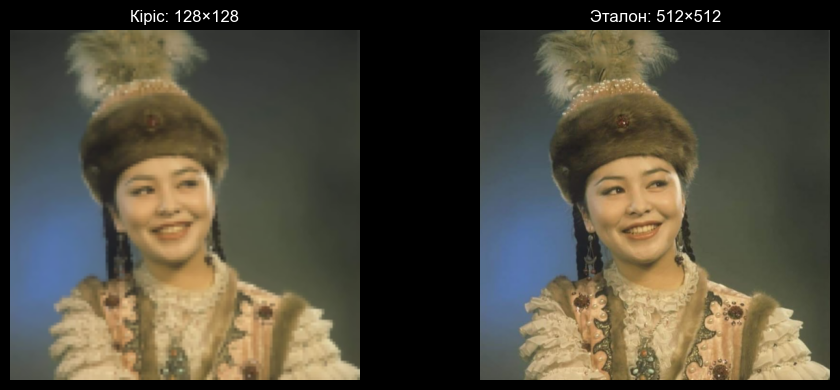

In [19]:
# Эталон сурет (RGB, uint8): Қыз Жібек суреті
reference_path = "qyz_zhibek.jpg"
reference_bgr = cv2.imread(reference_path, cv2.IMREAD_COLOR)
if reference_bgr is None:
    raise FileNotFoundError(f"Файл табылмады: {reference_path}. Суретті notebook бумасына көшіріңіз.")
reference = cv2.cvtColor(reference_bgr, cv2.COLOR_BGR2RGB)

# Суретті ортасынан шаршы етіп қию
h, w = reference.shape[:2]
side = min(h, w)
top, left = (h - side) // 2, (w - side) // 2
reference = reference[top:top + side, left:left + side]
reference = cv2.resize(reference, (512, 512), interpolation=cv2.INTER_AREA)

# Төмен ажыратымдылықтағы кіріс суреті: 4 есе кішірейтілген
low_res = cv2.resize(reference, (128, 128), interpolation=cv2.INTER_AREA)

print("Эталон өлшемі:", reference.shape)
print("Төмен ажыратымдылықтағы сурет:", low_res.shape)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(low_res)
plt.title("Кіріс: 128×128")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reference)
plt.title("Эталон: 512×512")
plt.axis("off")
plt.tight_layout()
plt.show()

## 6. Суретті GAN моделімен жақсарту

Real-ESRGAN интерфейсі BGR форматында сурет қабылдайды, сондықтан RGB↔BGR түрлендіруін орындаймыз.

In [20]:
low_res_bgr = cv2.cvtColor(low_res, cv2.COLOR_RGB2BGR)

# Модель арқылы 4 есе үлкейту
enhanced_bgr, _ = upsampler.enhance(low_res_bgr, outscale=4)
enhanced = cv2.cvtColor(enhanced_bgr, cv2.COLOR_BGR2RGB)

# Салыстыру үшін кәдімгі bicubic үлкейту
bicubic = cv2.resize(low_res, (512, 512), interpolation=cv2.INTER_CUBIC)

# Егер модельдің шығыс өлшемі өзгеше болса, метрика алдында эталон өлшеміне келтіреміз
if enhanced.shape[:2] != reference.shape[:2]:
    enhanced = cv2.resize(enhanced, (reference.shape[1], reference.shape[0]),
                          interpolation=cv2.INTER_CUBIC)

print("Real-ESRGAN нәтижесінің өлшемі:", enhanced.shape)

Real-ESRGAN нәтижесінің өлшемі: (512, 512, 3)


## 7. Нәтижелерді визуалды салыстыру

Төрт суретті қатар қараймыз: төмен сапалы кіріс, bicubic әдісі, Real-ESRGAN нәтижесі және эталон.

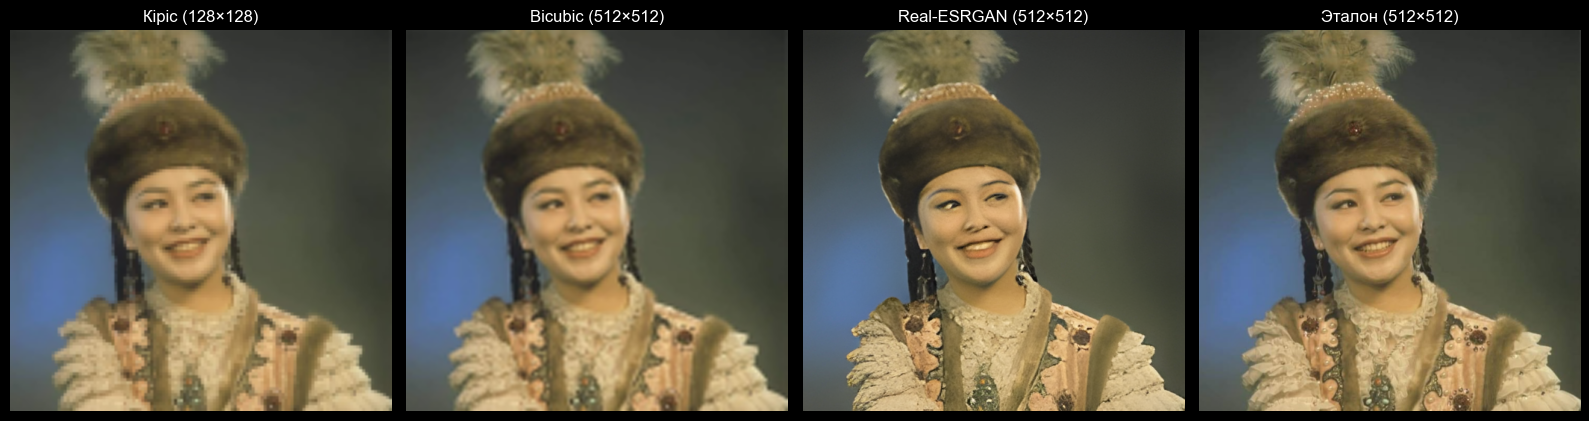

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
images = [low_res, bicubic, enhanced, reference]
titles = [
    "Кіріс (128×128)",
    "Bicubic (512×512)",
    "Real-ESRGAN (512×512)",
    "Эталон (512×512)"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 8. PSNR және SSIM арқылы бағалау

- **PSNR** — пиксельдік қателікке сүйенетін сапа көрсеткіші; әдетте жоғары болғаны жақсы.
- **SSIM** — жарықтық, контраст және құрылым ұқсастығын бағалайды; 1-ге жақын болғаны жақсы.

Екі метриканы да бірдей өлшемдегі суреттер арасында есептейміз. Bicubic — дәстүрлі үлкейту әдісімен салыстыру базасы.

In [22]:
def calculate_metrics(prediction, target):
    # Метрикалар бірдей өлшемдегі RGB суреттерге есептеледі
    prediction = np.asarray(prediction, dtype=np.uint8)
    target = np.asarray(target, dtype=np.uint8)

    psnr_value = peak_signal_noise_ratio(target, prediction, data_range=255)
    ssim_value = structural_similarity(
        target, prediction, channel_axis=2, data_range=255
    )
    return psnr_value, ssim_value

bicubic_psnr, bicubic_ssim = calculate_metrics(bicubic, reference)
gan_psnr, gan_ssim = calculate_metrics(enhanced, reference)

print(f"Bicubic  | PSNR: {bicubic_psnr:.3f} dB | SSIM: {bicubic_ssim:.4f}")
print(f"Real-ESRGAN | PSNR: {gan_psnr:.3f} dB | SSIM: {gan_ssim:.4f}")

Bicubic  | PSNR: 33.064 dB | SSIM: 0.9211
Real-ESRGAN | PSNR: 29.073 dB | SSIM: 0.8669


## 9. Метрикаларды диаграммада көрсету

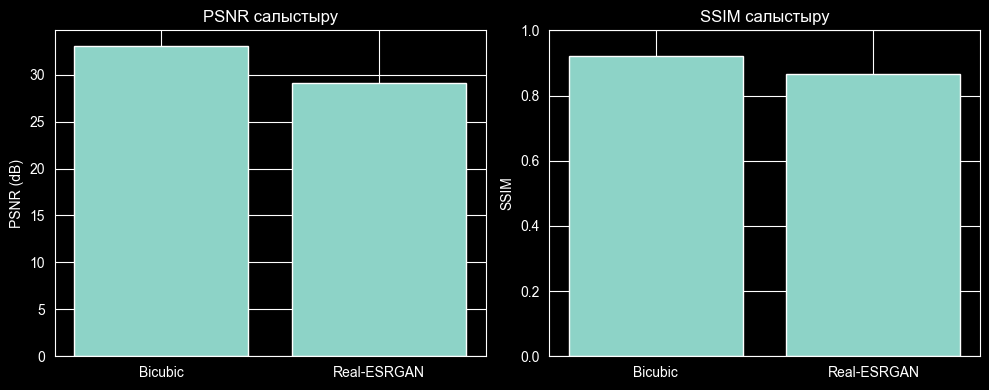

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

methods = ["Bicubic", "Real-ESRGAN"]
psnr_values = [bicubic_psnr, gan_psnr]
ssim_values = [bicubic_ssim, gan_ssim]

axes[0].bar(methods, psnr_values)
axes[0].set_title("PSNR салыстыру")
axes[0].set_ylabel("PSNR (dB)")

axes[1].bar(methods, ssim_values)
axes[1].set_title("SSIM салыстыру")
axes[1].set_ylabel("SSIM")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

## 10. Нәтижелерді сақтау

In [24]:
output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

Image.fromarray(low_res).save(output_dir / "input_low_resolution.png")
Image.fromarray(bicubic).save(output_dir / "bicubic_result.png")
Image.fromarray(enhanced).save(output_dir / "realesrgan_result.png")
Image.fromarray(reference).save(output_dir / "reference.png")

print("Нәтижелер сақталды:", output_dir.resolve())

Нәтижелер сақталды: C:\Users\User\Desktop\Gan\results


## 11. Өз суретіңізді өңдеу

1. Сурет файлын notebook тұрған бумаға көшіріңіз.
2. Төмендегі `input_path` мәнін өз файлыңыздың атауына ауыстырыңыз.
3. Ұяшықты орындаңыз. Нәтиже `results/my_image_enhanced.png` файлына сақталады.

Бұл бөлім тек суретті өңдейді. Егер бастапқы жоғары сапалы эталон сурет жоқ болса, PSNR/SSIM-ді сенімді түрде есептеу мүмкін емес.

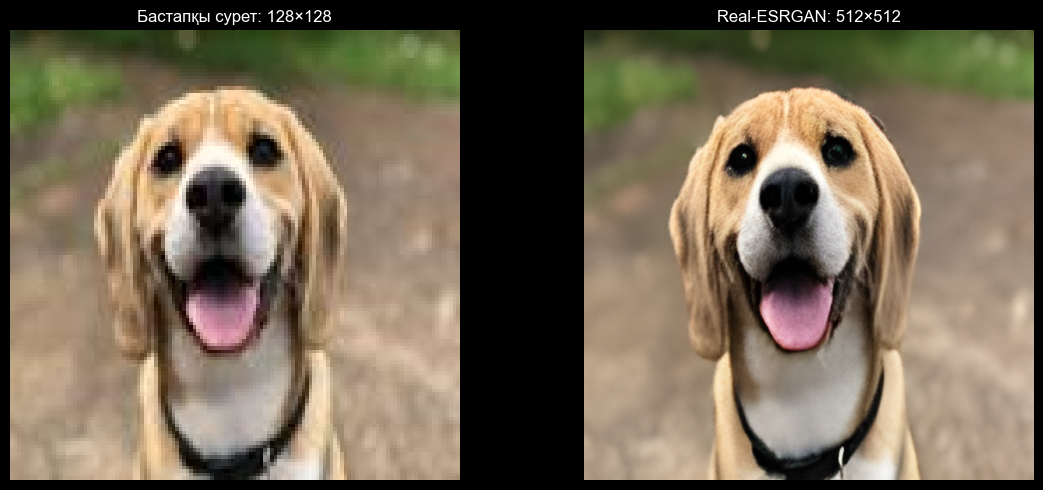

Өңделген сурет сақталды: C:\Users\User\Desktop\Gan\results\my_image_enhanced.png


In [25]:
input_path = "sobaka.jpg"  # Өз суретіңіздің файл атауын жазыңыз
output_path = output_dir / "my_image_enhanced.png"

if not Path(input_path).exists():
    print(f"Файл табылмады: {input_path}. Суретті notebook бумасына көшіріңіз.")
else:
    image_bgr = cv2.imread(input_path, cv2.IMREAD_COLOR)
    if image_bgr is None:
        raise ValueError("Сурет файлы оқылмады. JPG немесе PNG файл қолданып көріңіз.")

    result_bgr, _ = upsampler.enhance(image_bgr, outscale=4)
    cv2.imwrite(str(output_path), result_bgr)

    original_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    result_rgb = cv2.cvtColor(result_bgr, cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(original_rgb)
    axes[0].set_title(f"Бастапқы сурет: {original_rgb.shape[1]}×{original_rgb.shape[0]}")
    axes[0].axis("off")

    axes[1].imshow(result_rgb)
    axes[1].set_title(f"Real-ESRGAN: {result_rgb.shape[1]}×{result_rgb.shape[0]}")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()
    print("Өңделген сурет сақталды:", output_path.resolve())